In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Matching the team's Zero-Rule baseline implementation
class ZeroRuleClassifier(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.classes_, counts = np.unique(y, return_counts=True)
        self.majority_class_ = self.classes_[np.argmax(counts)]
        return self
    def predict(self, X):
        return np.array([self.majority_class_] * len(X))
    def score(self, X, y):
        preds = self.predict(X)
        return np.mean(preds == y)

In [6]:
# Adjust the relative path depending on which folder your notebook sits in
train_path = "data_preparation/processed/train_cleaned.csv"
val_path = "data_preparation/processed/validation_cleaned.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

# Extract 520 WAP columns and target label
wap_cols = [c for c in train_df.columns if c.startswith("WAP")]
X_train_raw = train_df[wap_cols]
y_train_raw = train_df["LOCATION_CLASS"]

X_holdout_raw = val_df[wap_cols]
y_holdout = val_df["LOCATION_CLASS"]

# Stratified 80/20 train/test split (matching team seed)
X_train, X_test, y_train, y_test = train_test_split(
    X_train_raw, y_train_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_train_raw
)

# Standardize features using StandardScaler (fit on training only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout_raw)

print(f"Training split: {X_train_scaled.shape}")
print(f"Validation split (20%): {X_test_scaled.shape}")
print(f"Held-out test set: {X_holdout_scaled.shape}")

Training split: (15440, 520)
Validation split (20%): (3860, 520)
Held-out test set: (1111, 520)


In [7]:
baseline = ZeroRuleClassifier()
baseline.fit(X_train_scaled, y_train)

baseline_preds = baseline.predict(X_test_scaled)
print(f"Zero-Rule Validation Accuracy: {accuracy_score(y_test, baseline_preds)*100:.2f}%")
print(f"Zero-Rule Validation Macro-F1: {f1_score(y_test, baseline_preds, average='macro'):.4f}")

Zero-Rule Validation Accuracy: 14.04%
Zero-Rule Validation Macro-F1: 0.0189


In [8]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. k-NN Search
knn = KNeighborsClassifier()
knn_params = {
    "n_neighbors": [1, 3, 5, 7, 11, 15],
    "metric": ["euclidean", "manhattan"],
    "weights": ["uniform", "distance"],
}

print("Running GridSearchCV for k-NN...")
knn_grid = GridSearchCV(knn, knn_params, cv=cv_strategy, scoring="f1_macro", n_jobs=-1, verbose=1)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best k-NN CV Macro F1: {knn_grid.best_score_:.4f}")
print(f"Best k-NN Params: {knn_grid.best_params_}\n")

# 2. Random Forest Search
rf = RandomForestClassifier(random_state=42)
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 20, 35],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"],
}

print("Running GridSearchCV for Random Forest...")
rf_grid = GridSearchCV(rf, rf_params, cv=cv_strategy, scoring="f1_macro", n_jobs=-1, verbose=1)
rf_grid.fit(X_train_scaled, y_train)

print(f"Best RF CV Macro F1: {rf_grid.best_score_:.4f}")
print(f"Best RF Params: {rf_grid.best_params_}")

Running GridSearchCV for k-NN...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best k-NN CV Macro F1: 0.9932
Best k-NN Params: {'metric': 'manhattan', 'n_neighbors': 1, 'weights': 'uniform'}

Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best RF CV Macro F1: 0.9966
Best RF Params: {'max_depth': None, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 300}


In [10]:
models = {
    "Zero-Rule Baseline": baseline,
    "k-NN (Tuned)": knn_grid.best_estimator_,
    "Random Forest (Tuned)": rf_grid.best_estimator_,
}

results = []
for name, model in models.items():
    val_preds = model.predict(X_test_scaled)
    test_preds = model.predict(X_holdout_scaled)
    
    results.append({
        "Model": name,
        "Val Accuracy (%)": accuracy_score(y_test, val_preds) * 100,
        "Val Macro F1": f1_score(y_test, val_preds, average="macro"),
        "Holdout Accuracy (%)": accuracy_score(y_holdout, test_preds) * 100,
        "Holdout Macro F1": f1_score(y_holdout, test_preds, average="macro"),
    })

results_df = pd.DataFrame(results)

# Round values directly
results_df["Val Accuracy (%)"] = results_df["Val Accuracy (%)"].round(2)
results_df["Val Macro F1"] = results_df["Val Macro F1"].round(4)
results_df["Holdout Accuracy (%)"] = results_df["Holdout Accuracy (%)"].round(2)
results_df["Holdout Macro F1"] = results_df["Holdout Macro F1"].round(4)

display(results_df)

,Model,Val Accuracy (%),Val Macro F1,Holdout Accuracy (%),Holdout Macro F1
0,Zero-Rule Baseline,14.04,0.0189,3.60,0.0053
1,k-NN (Tuned),99.51,0.9947,84.34,0.8209
2,Random Forest (Tuned),99.56,0.9948,91.09,0.8969


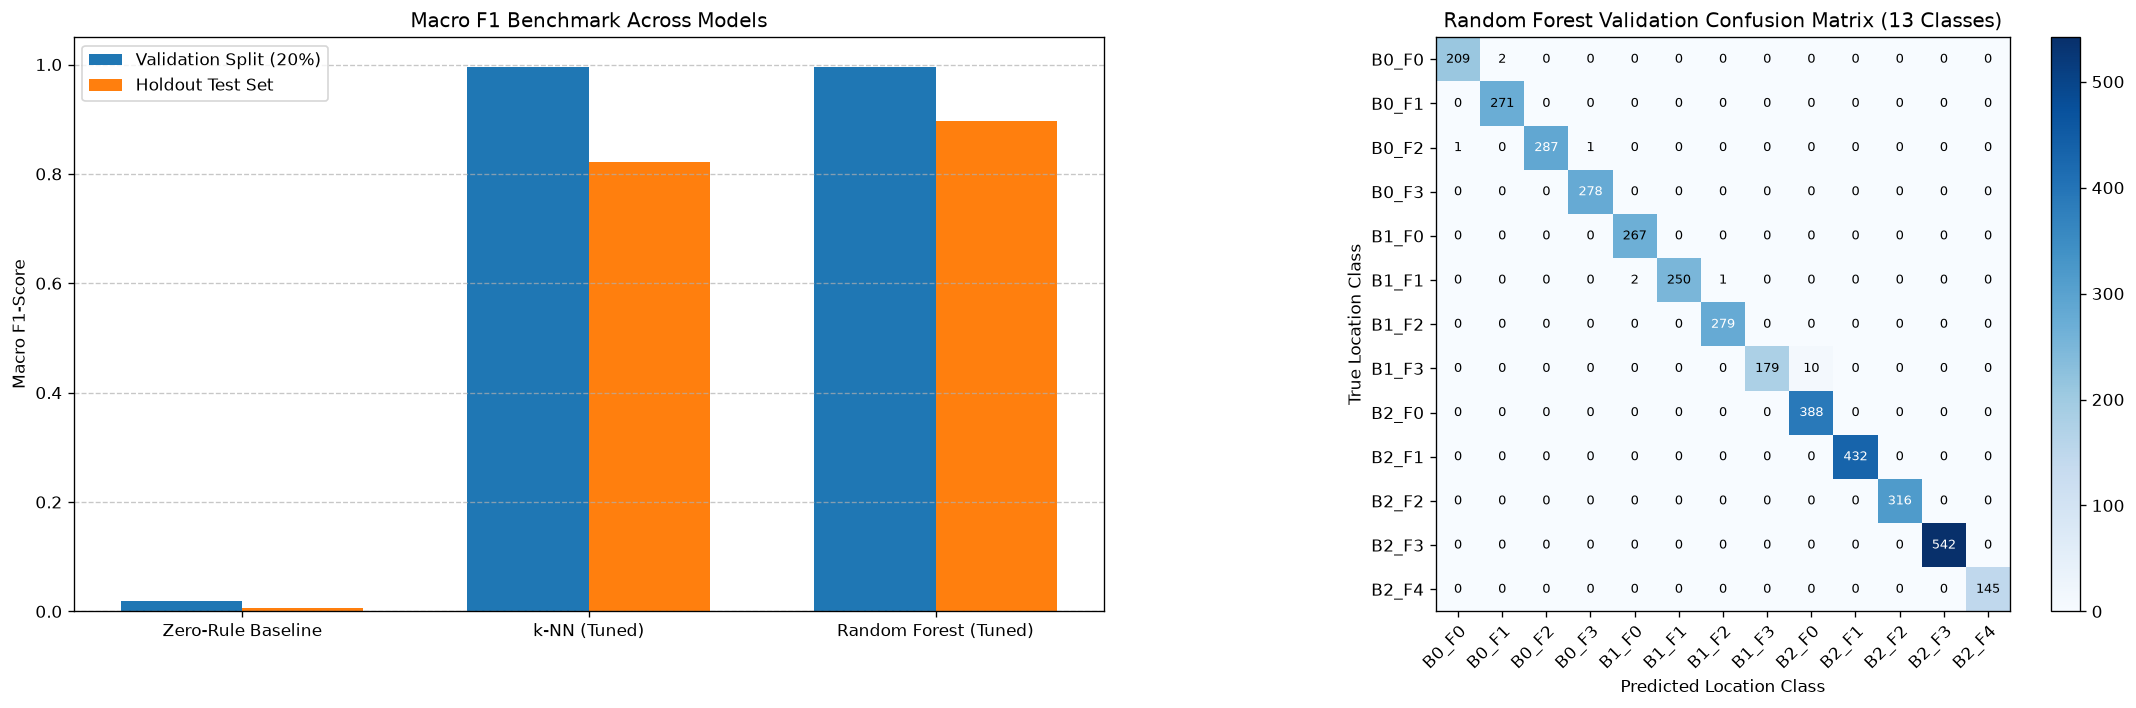

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Macro F1 comparison bar chart
model_labels = [r["Model"] for r in results]
val_f1_scores = [r["Val Macro F1"] for r in results]
holdout_f1_scores = [r["Holdout Macro F1"] for r in results]

x = np.arange(len(model_labels))
width = 0.35

axes[0].bar(x - width/2, val_f1_scores, width, label='Validation Split (20%)', color='#1f77b4')
axes[0].bar(x + width/2, holdout_f1_scores, width, label='Holdout Test Set', color='#ff7f0e')
axes[0].set_ylabel('Macro F1-Score')
axes[0].set_title('Macro F1 Benchmark Across Models')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_labels)
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Confusion Matrix for Random Forest on Validation Split
best_model = rf_grid.best_estimator_
val_preds = best_model.predict(X_test_scaled)
classes = np.unique(y_test)
cm = confusion_matrix(y_test, val_preds, labels=classes)

im = axes[1].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[1].figure.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set(
    xticks=np.arange(len(classes)),
    yticks=np.arange(len(classes)),
    xticklabels=classes,
    yticklabels=classes,
    title='Random Forest Validation Confusion Matrix (13 Classes)',
    ylabel='True Location Class',
    xlabel='Predicted Location Class',
)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[1].text(
            j, i, format(cm[i, j], 'd'),
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black",
            fontsize=8,
        )

plt.tight_layout()
plt.show()